# Pipeline tổng quát: Phân cụm khách hàng bằng RFM + K-Means

```
====================================================================
PIPELINE TỔNG QUÁT: PHÂN CỤM KHÁCH HÀNG BẰNG RFM + K-MEANS
Chạy được trên NHIỀU bộ dữ liệu giao dịch bán lẻ khác nhau
(Online Retail - UCI, Supermarket - Kaggle, hoặc dataset khác),
miễn là dữ liệu có các trường: khách hàng, giao dịch, ngày, và
số tiền/số lượng+đơn giá.

CÁCH HOẠT ĐỘNG:
- Bạn CHỈ cần sửa phần CONFIG bên dưới khi đổi sang bộ dữ liệu khác.
- Nếu để COLUMN_MAP = None cho một vai trò nào đó, chương trình sẽ
  TỰ ĐỘNG dò tên cột phù hợp dựa trên danh sách từ khóa thường gặp
  (CANDIDATES). Nếu dò sai hoặc không tìm thấy, bạn tự điền tên cột
  chính xác vào COLUMN_MAP để ép buộc dùng đúng cột đó.
- Toàn bộ 7 giai đoạn xử lý bên dưới đều thao tác trên các cột đã
  được CHUẨN HÓA TÊN (CUSTOMER_ID, TXN_ID, DATE, AMOUNT...), nên
  logic xử lý không cần sửa khi đổi dataset.

Yêu cầu thư viện:
    pip install pandas numpy scikit-learn matplotlib seaborn --break-system-packages
```

## Cài đặt thư viện (Colab đã có sẵn hầu hết, chạy nếu thiếu)

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import thư viện & hàm tiện ích

In [2]:
import os
import codecs
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, MeanShift, estimate_bandwidth, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, pairwise_distances
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (kích hoạt chế độ vẽ 3D)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

%matplotlib inline

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
def fmt_num(x, decimals=0):
    """Định dạng số có dấu phẩy ngăn cách hàng nghìn, dễ đọc hơn số thô."""
    if pd.isna(x):
        return "—"
    return f"{x:,.{decimals}f}"


def print_section(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)


def compute_cluster_metrics(X, labels):
    """Tính các chỉ số đánh giá chất lượng phân cụm (dùng chung cho stage4b và stage5)."""
    mask = labels != -1
    X_valid, labels_valid = X[mask], labels[mask]
    if len(set(labels_valid)) < 2:
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {
        "silhouette": silhouette_score(X_valid, labels_valid),
        "davies_bouldin": davies_bouldin_score(X_valid, labels_valid),
        "calinski_harabasz": calinski_harabasz_score(X_valid, labels_valid),
    }

## 0. CONFIG — phần duy nhất cần sửa khi đổi bộ dữ liệu

In [4]:
# ====================================================================
# 0. CONFIG — PHẦN DUY NHẤT CẦN SỬA KHI ĐỔI BỘ DỮ LIỆU
# ====================================================================
DATA_PATH = r"D:\archive (6)\supermarket_large_dataset.csv"     # <-- Đường dẫn tới file CSV của bạn
OUTPUT_DIR = "outputs_rfm"
RANDOM_STATE = 42
FINAL_K = None                    # None = tự động dùng best_k từ Giai đoạn 4 (Silhouette). Đặt số cụ thể (vd: 4) để ép buộc.
RUN_ALGORITHM_COMPARISON = True   # True: chạy Giai đoạn 4.5 so sánh 6 thuật toán phân cụm (giống bài báo JABES)
MAX_SAMPLE_FOR_HEAVY_ALGOS = 3000  # Spectral Clustering, Mean Shift và Dunn Index chạy chậm với dữ liệu lớn -> lấy mẫu tối đa chừng này khách hàng

# Khai báo TÊN CỘT THẬT trong file của bạn. Để None để tự động dò.
# Ví dụ ép buộc thủ công: "customer_id": "MaKhachHang"
COLUMN_MAP = {
    "customer_id":    None,   # Mã khách hàng (bắt buộc)
    "transaction_id": None,   # Mã đơn hàng/hóa đơn/giỏ hàng, dùng để đếm Frequency (bắt buộc)
    "date":           None,   # Ngày giao dịch (bắt buộc)
    "quantity":       None,   # Số lượng (tùy chọn — cần nếu không có sẵn cột amount)
    "unit_price":     None,   # Đơn giá (tùy chọn — cần nếu không có sẵn cột amount)
    "amount":         None,   # Tổng tiền dòng giao dịch, nếu dataset đã tính sẵn (tùy chọn, ưu tiên dùng nếu có)
}

# Các cột "nhãn có sẵn" (ground truth) muốn đối chiếu ở Giai đoạn 6, nếu có trong data.
# Để trống [] nếu dataset không có, hoặc để None để tự động dò các cột có tên gợi ý phân khúc/churn/CLV.
EXTRA_LABEL_COLUMNS = None

### (Tùy chọn) Tải file dữ liệu lên runtime Colab
Khi chạy trên Colab, đường dẫn `D:\...` trên máy bạn **không tồn tại** trên runtime.
Cell dưới sẽ mở hộp thoại upload nếu không tìm thấy `DATA_PATH`
(hoặc bạn tự upload file vào `/content/` rồi sửa `DATA_PATH`).

In [5]:
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = "/content/" + next(iter(uploaded))
    except Exception as e:
        print("Không mở được hộp thoại upload:", e)
        print("=> Hãy upload CSV vào /content/ thủ công rồi sửa DATA_PATH.")

print("IN_COLAB =", IN_COLAB, "| DATA_PATH =", DATA_PATH, "| tồn tại:", os.path.exists(DATA_PATH))
os.makedirs(OUTPUT_DIR, exist_ok=True)

IN_COLAB = False | DATA_PATH = D:\archive (6)\supermarket_large_dataset.csv | tồn tại: True


## 1. Từ điển từ khóa dùng để tự động dò tên cột

In [6]:
CANDIDATES = {
    "customer_id":    ["customer_id", "customerid", "cust_id", "client_id",
                        "user_id", "userid", "member_id", "id_khach_hang", "makhachhang"],
    "transaction_id": ["basket_id", "invoice_no", "invoiceno", "invoice_id", "order_id",
                        "transaction_id", "receipt_id", "bill_id", "billno", "ma_hoa_don"],
    "date":           ["transaction_date", "invoice_date", "order_date", "purchase_date",
                        "transaction_datetime", "invoicedate", "date", "ngay_giao_dich"],
    "quantity":       ["quantity", "qty", "units", "unit_sold", "quantity_sold", "so_luong"],
    "unit_price":     ["unit_price", "unitprice", "price", "selling_price", "don_gia"],
    "amount":         ["total_amount", "net_sales", "sales_amount", "total_price", "totalprice",
                        "amount", "sales_revenue", "gross_sales", "line_total", "thanh_tien"],
}

LABEL_HINTS = ["segment", "churn", "lifetime_value", "clv", "loyalty_tier",
               "membership_tier", "retention", "risk_category"]

In [7]:
def detect_encoding(path, _cache={}):
    """Tự dò encoding của file CSV (utf-8, utf-8-sig, cp1252, cuối cùng latin-1).
    Chỉ đọc 2 MB đầu để tiết kiệm I/O; cache kết quả theo đường dẫn."""
    if path in _cache:
        return _cache[path]
    for enc in ["utf-8", "utf-8-sig", "cp1252"]:
        dec = codecs.getincrementaldecoder(enc)()
        try:
            with open(path, "rb") as f:
                sample = f.read(2 << 20)  # 2 MB đủ để nhận dạng encoding
                dec.decode(sample, final=(len(sample) < 2 << 20))
            _cache[path] = enc
            return enc
        except UnicodeDecodeError:
            continue
    _cache[path] = "latin-1"
    return "latin-1"


def detect_column(columns, role, forced=None):
    """Tìm tên cột thật khớp với một 'vai trò' logic (customer_id, date...).
    Ưu tiên: tên do người dùng ép buộc > khớp chính xác (không phân biệt hoa/thường)
    > khớp một phần (substring)."""
    if forced:
        if forced in columns:
            return forced
        raise ValueError(f"Cột '{forced}' bạn khai báo cho vai trò '{role}' không tồn tại trong file dữ liệu.")

    lower_map = {c.lower(): c for c in columns}
    for cand in CANDIDATES.get(role, []):
        if cand in lower_map:
            return lower_map[cand]
    for c in columns:
        for cand in CANDIDATES.get(role, []):
            if cand in c.lower():
                return c
    return None


def detect_label_columns(columns, forced_list=None):
    """Tự động tìm các cột nhãn khách hàng (segment/churn/CLV...) để đối chiếu ở Giai đoạn 6.
    Bỏ qua các cột thuộc tính sản phẩm (product_*) vì không phải nhãn của khách hàng."""
    if forced_list is not None:
        return [c for c in forced_list if c in columns]
    found = []
    for c in columns:
        cl = c.lower()
        if cl.startswith("product"):
            continue
        if any(hint in cl for hint in LABEL_HINTS):
            found.append(c)
    return found

## Giai đoạn 0: Dò cột & báo cáo mapping

In [8]:
def stage0_resolve_columns(path: str, column_map: dict, extra_label_columns):
    print_section("GIAI ĐOẠN 0: DÒ TÊN CỘT TỰ ĐỘNG")

    header = pd.read_csv(path, nrows=0, encoding=detect_encoding(path)).columns.tolist()

    resolved = {}
    for role in ["customer_id", "transaction_id", "date", "quantity", "unit_price", "amount"]:
        col = detect_column(header, role, forced=column_map.get(role))
        resolved[role] = col
        trang_thai = "OK" if col else ("BẮT BUỘC nhưng KHÔNG TÌM THẤY" if role in
                                        ("customer_id", "transaction_id", "date") else "không có (tùy chọn)")
        print(f"  {role:15s} -> {str(col):25s} [{trang_thai}]")

    # Kiểm tra các cột bắt buộc
    required = ["customer_id", "transaction_id", "date"]
    missing_required = [r for r in required if resolved[r] is None]
    if missing_required:
        raise ValueError(
            f"Không tự dò được các cột bắt buộc: {missing_required}.\n"
            f"=> Hãy mở file dữ liệu, xem tên cột thật, rồi điền thủ công vào COLUMN_MAP ở đầu script."
        )

    # Kiểm tra đủ điều kiện tính Monetary: cần 'amount' HOẶC cả 'quantity' + 'unit_price'
    if not resolved["amount"] and not (resolved["quantity"] and resolved["unit_price"]):
        raise ValueError(
            "Không đủ dữ liệu để tính Monetary: cần có cột tổng tiền (amount) "
            "HOẶC cả hai cột quantity + unit_price. Hãy điền thủ công vào COLUMN_MAP."
        )

    labels = detect_label_columns(header, extra_label_columns)
    print(f"\n  Cột nhãn có sẵn để đối chiếu (Giai đoạn 6): {labels if labels else 'Không tìm thấy / không dùng'}")

    return resolved, labels

## Giai đoạn 1: Thu thập & mô tả dữ liệu (Data Understanding)

In [9]:
def stage1_load_and_explore(path: str, resolved: dict, labels: list) -> pd.DataFrame:
    print_section("GIAI ĐOẠN 1: THU THẬP & MÔ TẢ DỮ LIỆU")

    usecols = [c for c in resolved.values() if c] + labels
    usecols = list(dict.fromkeys(usecols))  # loại trùng, giữ thứ tự

    df = pd.read_csv(path, usecols=usecols, encoding=detect_encoding(path))

    # Đổi tên cột về dạng chuẩn nội bộ, để các giai đoạn sau không phụ thuộc dataset gốc
    rename_map = {resolved[role]: role.upper() for role in
                  ["customer_id", "transaction_id", "date", "quantity", "unit_price", "amount"]
                  if resolved[role]}
    df = df.rename(columns=rename_map)
    df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

    print(f"  {'Số dòng dữ liệu:':32s} {fmt_num(len(df))}")
    print(f"  {'Số cột:':32s} {df.shape[1]}")
    print(f"  {'Khoảng thời gian:':32s} {df['DATE'].min().date()}  ->  {df['DATE'].max().date()}")
    print(f"  {'Số khách hàng duy nhất:':32s} {fmt_num(df['CUSTOMER_ID'].nunique())}")
    print(f"  {'Số giao dịch duy nhất:':32s} {fmt_num(df['TRANSACTION_ID'].nunique())}")

    # Kiểm tra chất lượng mã giao dịch: 1 mã phải thuộc về 1 khách hàng
    shared = (df.groupby("TRANSACTION_ID")["CUSTOMER_ID"].nunique() > 1).mean() * 100
    print(f"  {'% mã giao dịch dùng chung nhiều KH:':32s} {shared:.1f}%")
    if shared > 5:
        print("  [CẢNH BÁO] TRANSACTION_ID bị nhiều khách hàng dùng chung -> không phải mã hóa đơn thật.")
        print("             Frequency sẽ được tính bằng số NGÀY MUA khác nhau của mỗi khách (FREQUENCY_MODE='auto').")

    # Phát hiện cột nhãn trùng nội dung (vd membership_tier == loyalty_tier)
    dup_cols = []
    for i, a in enumerate(labels):
        for b in labels[i + 1:]:
            if b not in dup_cols and df[a].equals(df[b]):
                dup_cols.append(b)
    if dup_cols:
        print(f"\n  Cột nhãn trùng nội dung, sẽ bỏ qua: {dup_cols}")
        df = df.drop(columns=dup_cols)
        labels[:] = [c for c in labels if c not in dup_cols]

    missing = (df.isna().mean() * 100).round(2)
    missing = missing[missing > 0].sort_values(ascending=False)
    if len(missing) > 0:
        print("\n  Cột có dữ liệu thiếu:")
        for col, pct in missing.items():
            print(f"    - {col:20s}: {pct:5.2f} %")
    else:
        print("\n  Không có cột nào thiếu dữ liệu.")

    df.attrs["shared_txn_pct"] = shared
    return df

## Giai đoạn 2: Làm sạch & tiền xử lý (Data Preparation)

In [10]:
def stage2_clean_data(df: pd.DataFrame) -> pd.DataFrame:
    print_section("GIAI ĐOẠN 2: LÀM SẠCH & TIỀN XỬ LÝ DỮ LIỆU")

    n_before = len(df)
    attrs = dict(df.attrs)

    df = df.dropna(subset=["CUSTOMER_ID", "TRANSACTION_ID", "DATE"])

    if "QUANTITY" in df.columns:
        df = df[df["QUANTITY"] > 0]
    if "UNIT_PRICE" in df.columns:
        df = df[df["UNIT_PRICE"] > 0]

    df = df.drop_duplicates()

    # Tính LINE_TOTAL: ưu tiên cột AMOUNT có sẵn, nếu không thì quantity * unit_price
    if "AMOUNT" in df.columns and df["AMOUNT"].notna().any():
        df["LINE_TOTAL"] = df["AMOUNT"]
    else:
        df["LINE_TOTAL"] = df["QUANTITY"] * df["UNIT_PRICE"]

    df = df[df["LINE_TOTAL"] > 0]

    # LƯU Ý: không cắt ngoại lai ở mức dòng nữa (gây "trần" nhân tạo ở Monetary).
    # Ngoại lai được xử lý ở mức KHÁCH HÀNG (winsorize) trong Giai đoạn 3, kết hợp log1p ở Giai đoạn 4.
    pct_loai = (n_before - len(df)) / n_before * 100
    print(f"  {'Số dòng trước xử lý:':38s} {fmt_num(n_before)}")
    print(f"  {'Số dòng sau xử lý:':38s} {fmt_num(len(df))}  (đã loại {fmt_num(n_before - len(df))} dòng, {pct_loai:.1f}%)")

    df.attrs.update(attrs)
    return df

## Giai đoạn 3: Tính toán chỉ số RFM (Feature Engineering)

In [11]:
FREQUENCY_MODE = "auto"   # "auto": nếu TRANSACTION_ID bị dùng chung -> đếm số ngày mua; "transaction": luôn đếm mã giao dịch; "days": luôn đếm số ngày mua
MONETARY_WINSOR_PCT = 0.99  # Giới hạn Monetary ở phân vị này (mức khách hàng). None = không cắt

def stage3_compute_rfm(df: pd.DataFrame, labels: list) -> pd.DataFrame:
    print_section("GIAI ĐOẠN 3: TÍNH TOÁN CHỈ SỐ RFM")

    snapshot_date = df["DATE"].max() + pd.Timedelta(days=1)
    print(f"Ngày mốc tham chiếu (snapshot date): {snapshot_date.date()}")

    shared = df.attrs.get("shared_txn_pct", 0.0)
    use_days = FREQUENCY_MODE == "days" or (FREQUENCY_MODE == "auto" and shared > 5)
    print(f"  Cách tính Frequency: {'số NGÀY MUA khác nhau' if use_days else 'số mã giao dịch khác nhau'}")

    d = df.assign(_DAY=df["DATE"].dt.normalize())
    g = d.groupby("CUSTOMER_ID")
    rfm = pd.DataFrame({
        "Recency": (snapshot_date - g["DATE"].max()).dt.days,
        "Frequency": g["_DAY"].nunique() if use_days else g["TRANSACTION_ID"].nunique(),
        "Monetary": g["LINE_TOTAL"].sum(),
    }).reset_index()

    if MONETARY_WINSOR_PCT:
        cap = rfm["Monetary"].quantile(MONETARY_WINSOR_PCT)
        n_cap = (rfm["Monetary"] > cap).sum()
        rfm["Monetary"] = rfm["Monetary"].clip(upper=cap)
        print(f"  Winsorize Monetary mức khách hàng ở P{MONETARY_WINSOR_PCT*100:.0f} = {cap:,.2f} ({n_cap:,} khách bị giới hạn)")

    if labels:
        extra = df.groupby("CUSTOMER_ID")[labels].first().reset_index()
        rfm = rfm.merge(extra, on="CUSTOMER_ID", how="left")

    print(f"  {'Số khách hàng sau khi tính RFM:':32s} {fmt_num(len(rfm))}")

    desc = rfm[["Recency", "Frequency", "Monetary"]].describe().T
    print("\n  Thống kê mô tả 3 chỉ số RFM:")
    header = f"  {'Chỉ số':<12}{'Nhỏ nhất':>14}{'Trung vị':>14}{'Trung bình':>14}{'Lớn nhất':>16}"
    print(header)
    print("  " + "-" * (len(header) - 2))
    for idx in ["Recency", "Frequency", "Monetary"]:
        r = desc.loc[idx]
        dv = 2 if idx == "Monetary" else 0
        print(f"  {idx:<12}{fmt_num(r['min'], dv):>14}{fmt_num(r['50%'], dv):>14}{fmt_num(r['mean'], 1):>14}{fmt_num(r['max'], dv):>16}")

    rfm.to_csv(f"{OUTPUT_DIR}/rfm_table.csv", index=False)
    print(f"\n  Đã lưu bảng RFM vào: {OUTPUT_DIR}/rfm_table.csv")

    return rfm

## Giai đoạn 4: Chuẩn hóa & xác định số cụm tối ưu

In [12]:
def stage4_scale_and_find_k(rfm: pd.DataFrame, k_range=range(2, 9), sil_sample=10000):
    print_section("GIAI ĐOẠN 4: CHUẨN HÓA DỮ LIỆU & XÁC ĐỊNH SỐ CỤM TỐI ƯU")

    rfm_log = rfm[["Recency", "Frequency", "Monetary"]].apply(lambda x: np.log1p(x))
    scaler = StandardScaler()
    rfm_scaled = scaler.fit_transform(rfm_log)

    wcss, silhouette_scores = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        lb = km.fit_predict(rfm_scaled)
        wcss.append(km.inertia_)
        # Silhouette O(n^2): dùng mẫu cố định để nhanh mà vẫn ổn định
        sil = silhouette_score(rfm_scaled, lb, sample_size=min(sil_sample, len(rfm_scaled)), random_state=RANDOM_STATE)
        silhouette_scores.append(sil)

    best_idx = int(np.argmax(silhouette_scores))
    print(f"  {'k':>3}{'WCSS':>14}{'Silhouette':>14}")
    print("  " + "-" * 31)
    for i, k in enumerate(k_range):
        danh_dau = "  <- cao nhất" if i == best_idx else ""
        print(f"  {k:>3}{fmt_num(wcss[i], 1):>14}{silhouette_scores[i]:>14.3f}{danh_dau}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(list(k_range), wcss, marker="o")
    axes[0].set_title("Phương pháp Elbow (WCSS)")
    axes[0].set_xlabel("Số cụm (k)")
    axes[1].plot(list(k_range), silhouette_scores, marker="o", color="orange")
    axes[1].set_title("Chỉ số Silhouette theo k")
    axes[1].set_xlabel("Số cụm (k)")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/elbow_silhouette.png", dpi=150)
    plt.show()

    best_k = list(k_range)[best_idx]
    print(f"\n  >>> Số cụm đề xuất theo Silhouette cao nhất: k = {best_k}")
    print(f"  >>> Lưu ý: nên đối chiếu thêm với biểu đồ Elbow và khả năng diễn giải kinh doanh trước khi chốt k.")

    return rfm_scaled, best_k

## Giai đoạn 4.5: So sánh nhiều thuật toán phân cụm (JABES 2025)

In [13]:
def _dunn_index(X, labels, max_sample=MAX_SAMPLE_FOR_HEAVY_ALGOS, random_state=RANDOM_STATE):
    """Dunn Index = khoảng cách nhỏ nhất giữa 2 cụm khác nhau / khoảng cách lớn nhất trong nội bộ 1 cụm.
    Càng CAO càng tốt. Tính trên toàn bộ dữ liệu tốn O(n^2) bộ nhớ nên với dữ liệu lớn sẽ lấy mẫu."""
    X, labels = np.asarray(X), np.asarray(labels)
    if len(X) > max_sample:
        rng = np.random.RandomState(random_state)
        idx = rng.choice(len(X), max_sample, replace=False)
        X, labels = X[idx], labels[idx]

    valid = labels != -1  # bỏ điểm nhiễu của DBSCAN (nhãn -1)
    X, labels = X[valid], labels[valid]
    unique_labels = np.unique(labels)
    if len(unique_labels) < 2:
        return np.nan

    # Tính từng cặp cụm riêng thay vì cấp phát ma trận N×N đầy đủ
    cluster_indices = {lb: np.where(labels == lb)[0] for lb in unique_labels}

    max_intra = 0.0
    for lb, idx in cluster_indices.items():
        if len(idx) > 1:
            D_intra = pairwise_distances(X[idx])
            max_intra = max(max_intra, D_intra.max())

    min_inter = np.inf
    labels_list = list(unique_labels)
    for i, l1 in enumerate(labels_list):
        for l2 in labels_list[i + 1:]:
            D_inter = pairwise_distances(X[cluster_indices[l1]], X[cluster_indices[l2]])
            min_inter = min(min_inter, D_inter.min())

    return min_inter / max_intra if max_intra > 0 else np.nan


def _fuzzy_c_means(X, c, m=2.0, max_iter=150, tol=1e-5, random_state=RANDOM_STATE):
    """Cài đặt gọn của thuật toán Fuzzy C-Means (không cần thư viện ngoài).
    Trả về nhãn cụm cứng (mỗi điểm gán vào cụm có độ thuộc cao nhất)."""
    if m <= 1.0:
        raise ValueError("Tham số fuzziness m phải > 1.0 (thường dùng m=2.0)")
    rng = np.random.RandomState(random_state)
    n = X.shape[0]
    u = rng.rand(n, c)
    u /= u.sum(axis=1, keepdims=True)

    for _ in range(max_iter):
        um = u ** m
        centers = (um.T @ X) / um.sum(axis=0)[:, None]
        dist = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
        dist = np.fmax(dist, 1e-10)
        new_u = 1.0 / (dist ** (2.0 / (m - 1)))
        new_u /= new_u.sum(axis=1, keepdims=True)
        if np.linalg.norm(new_u - u) < tol:
            u = new_u
            break
        u = new_u

    return np.argmax(u, axis=1)

In [14]:
def stage4b_compare_algorithms(rfm_scaled: np.ndarray, k: int):
    """So sánh 6 thuật toán bằng 4 chỉ số, TẤT CẢ được chấm trên CÙNG một mẫu khách hàng
    (kích thước tối đa MAX_SAMPLE_FOR_HEAVY_ALGOS) để các chỉ số (nhất là Calinski-Harabasz,
    phụ thuộc số điểm n) có thể so sánh công bằng. K-Means, GMM, FCM, DBSCAN vẫn được huấn luyện
    trên toàn bộ dữ liệu; Spectral và Mean Shift huấn luyện trên mẫu vì chạy chậm."""
    print_section("GIAI ĐOẠN 4.5: SO SÁNH NHIỀU THUẬT TOÁN PHÂN CỤM")

    n = len(rfm_scaled)
    if n > MAX_SAMPLE_FOR_HEAVY_ALGOS:
        rng = np.random.RandomState(RANDOM_STATE)
        idx = rng.choice(n, MAX_SAMPLE_FOR_HEAVY_ALGOS, replace=False)
        print(f"  Các chỉ số được chấm trên CÙNG mẫu {MAX_SAMPLE_FOR_HEAVY_ALGOS:,}/{n:,} khách hàng.")
    else:
        idx = np.arange(n)
    X_eval = rfm_scaled[idx]

    algorithms = {}  # tên -> (nhãn trên mẫu đánh giá, nhãn đầy đủ hoặc None)

    print("  Đang chạy K-Means...")
    _kmeans_labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(rfm_scaled)
    algorithms["K-Means"] = _kmeans_labels[idx]

    print("  Đang chạy Spectral Clustering (trên mẫu)...")
    try:
        algorithms["Spectral Clustering"] = SpectralClustering(
            n_clusters=k, affinity="nearest_neighbors", n_neighbors=10,
            assign_labels="kmeans", random_state=RANDOM_STATE).fit_predict(X_eval)
    except Exception as e:
        print(f"    [Bỏ qua] Spectral Clustering lỗi: {e}")

    print("  Đang chạy Mean Shift (trên mẫu)...")
    try:
        bandwidth = estimate_bandwidth(X_eval, quantile=0.2, random_state=RANDOM_STATE)
        if bandwidth <= 0:
            bandwidth = None
        algorithms["Mean Shift"] = MeanShift(bandwidth=bandwidth).fit_predict(X_eval)
    except Exception as e:
        print(f"    [Bỏ qua] Mean Shift lỗi: {e}")

    print("  Đang chạy Gaussian Mixture Model (GMM)...")
    algorithms["GMM"] = GaussianMixture(n_components=k, random_state=RANDOM_STATE).fit_predict(rfm_scaled)[idx]

    print("  Đang chạy DBSCAN...")
    algorithms["DBSCAN"] = DBSCAN(eps=0.5, min_samples=10).fit_predict(rfm_scaled)[idx]

    print("  Đang chạy Fuzzy C-Means (FCM)...")
    algorithms["FCM"] = _fuzzy_c_means(rfm_scaled, c=k, random_state=RANDOM_STATE)[idx]

    rows = []
    label_store = {}
    for name, labels in algorithms.items():
        label_store[name] = (labels, X_eval)
        n_clusters = len(set(labels) - {-1})
        noise_pct = (labels == -1).mean() * 100
        base = {"Thuật toán": name, "Số cụm": n_clusters, "Nhiễu(%)": round(noise_pct, 1)}
        if n_clusters < 2:
            rows.append({**base, "Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan,
                         "Dunn": np.nan, "Nhận xét": "Không đủ cụm để tính chỉ số (< 2 cụm)"})
            continue

        mask = labels != -1
        m = compute_cluster_metrics(X_eval, labels)
        dunn = _dunn_index(X_eval[mask], labels[mask])
        nx = "Nhiễu cao, chỉ số chỉ tính trên điểm không nhiễu" if noise_pct > 10 else ""
        rows.append({**base, "Silhouette": round(m["silhouette"], 3), "Davies-Bouldin": round(m["davies_bouldin"], 3),
                     "Calinski-Harabasz": round(m["calinski_harabasz"], 1),
                     "Dunn": round(dunn, 3) if not np.isnan(dunn) else np.nan, "Nhận xét": nx})

    result = pd.DataFrame(rows).set_index("Thuật toán")

    valid_rows = result.dropna(subset=["Silhouette"])
    if len(valid_rows) > 0:
        rank = (valid_rows["Silhouette"].rank(ascending=False)
                + valid_rows["Davies-Bouldin"].rank(ascending=True)
                + valid_rows["Calinski-Harabasz"].rank(ascending=False))
        best_algo = rank.idxmin()
        old = result.loc[best_algo, "Nhận xét"]
        result.loc[best_algo, "Nhận xét"] = ("<< Đề xuất: cân bằng tốt nhất giữa các chỉ số " + old).strip()

    print("\n  Bảng so sánh chất lượng phân cụm (tất cả chấm trên cùng một mẫu):")
    header = f"  {'Thuật toán':<20}{'Số cụm':>8}{'Nhiễu%':>8}{'Silhouette':>12}{'Davies-B.':>12}{'Calinski-H.':>14}{'Dunn':>9}"
    print(header)
    print("  " + "-" * (len(header) - 2))
    for algo, row in result.iterrows():
        sil = f"{row['Silhouette']:.3f}" if pd.notna(row["Silhouette"]) else "—"
        db = f"{row['Davies-Bouldin']:.3f}" if pd.notna(row["Davies-Bouldin"]) else "—"
        ch = fmt_num(row["Calinski-Harabasz"], 1) if pd.notna(row["Calinski-Harabasz"]) else "—"
        dunn = f"{row['Dunn']:.3f}" if pd.notna(row["Dunn"]) else "—"
        print(f"  {algo:<20}{row['Số cụm']:>8}{row['Nhiễu(%)']:>8.1f}{sil:>12}{db:>12}{ch:>14}{dunn:>9}   {row['Nhận xét']}")

    result.to_csv(f"{OUTPUT_DIR}/algorithm_comparison.csv")
    print(f"\n  Đã lưu bảng so sánh vào: {OUTPUT_DIR}/algorithm_comparison.csv")

    _visualize_algorithm_metrics(result)
    _visualize_algorithm_comparison(label_store)

    return result, label_store, _kmeans_labels

In [15]:
def _visualize_algorithm_metrics(result: pd.DataFrame):
    """Vẽ 4 biểu đồ cột so sánh Silhouette, Davies-Bouldin, Calinski-Harabasz, Dunn
    giữa các thuật toán — giúp nhìn nhanh thuật toán nào vượt trội mà không cần đọc bảng số."""
    metrics = [
        ("Silhouette", "Càng CAO càng tốt", "#2E7D32"),
        ("Davies-Bouldin", "Càng THẤP càng tốt", "#C62828"),
        ("Calinski-Harabasz", "Càng CAO càng tốt", "#1565C0"),
        ("Dunn", "Càng CAO càng tốt", "#EF6C00"),
    ]
    plot_df = result.dropna(subset=["Silhouette"])
    if plot_df.empty:
        print("  [Bỏ qua vẽ biểu đồ so sánh chỉ số] Không có thuật toán nào đủ điều kiện tính chỉ số.")
        return

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for ax, (col, ghi_chu, color) in zip(axes, metrics):
        vals = plot_df[col]
        bars = ax.bar(vals.index, vals.values, color=color, alpha=0.85)
        best_idx = vals.idxmax() if "CAO" in ghi_chu else vals.idxmin()
        bars[list(vals.index).index(best_idx)].set_edgecolor("black")
        bars[list(vals.index).index(best_idx)].set_linewidth(2.5)
        ax.set_title(f"{col}\n({ghi_chu})", fontsize=10.5, fontweight="bold")
        ax.tick_params(axis="x", rotation=35)
        for label in ax.get_xticklabels():
            label.set_ha("right")
        ax.grid(axis="y", alpha=0.3)
        for i, v in enumerate(vals.values):
            ax.text(i, v, f"{v:,.2f}" if col != "Calinski-Harabasz" else f"{v:,.0f}",
                    ha="center", va="bottom", fontsize=8)

    plt.suptitle("So sánh 4 chỉ số đánh giá chất lượng phân cụm giữa các thuật toán "
                  "(viền đen = thuật toán tốt nhất theo từng chỉ số)", fontsize=11, y=1.04)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/algorithm_comparison_metrics.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  Đã lưu biểu đồ so sánh chỉ số vào: {OUTPUT_DIR}/algorithm_comparison_metrics.png")


def _visualize_algorithm_comparison(label_store: dict):
    """Vẽ lưới scatter 3D (Recency-Frequency-Monetary đã chuẩn hóa) cho từng thuật toán,
    tương tự Hình 3 trong bài báo tham chiếu."""
    n_algo = len(label_store)
    n_cols = 3
    n_rows = int(np.ceil(n_algo / n_cols))

    fig = plt.figure(figsize=(5.5 * n_cols, 4.8 * n_rows))
    for i, (name, (labels, X_used)) in enumerate(label_store.items(), start=1):
        ax = fig.add_subplot(n_rows, n_cols, i, projection="3d")
        sc = ax.scatter(X_used[:, 0], X_used[:, 1], X_used[:, 2], c=labels, cmap="tab10", s=12, alpha=0.7)
        ax.set_title(name, fontsize=11, fontweight="bold")
        ax.set_xlabel("Recency (chuẩn hóa)", fontsize=8)
        ax.set_ylabel("Frequency (chuẩn hóa)", fontsize=8)
        ax.set_zlabel("Monetary (chuẩn hóa)", fontsize=8)

    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/algorithm_comparison_3d.png", dpi=150)
    plt.show()
    print(f"Đã lưu biểu đồ so sánh 3D vào: {OUTPUT_DIR}/algorithm_comparison_3d.png")

## Giai đoạn 5: Huấn luyện K-Means & gán nhãn cụm

In [16]:
def _name_clusters(summary: pd.DataFrame, rfm: pd.DataFrame) -> dict:
    """Đặt tên cụm theo HỒ SƠ R/F/M của từng cụm so với toàn bộ khách hàng (không phụ thuộc k):
      - recent: Recency TB thấp hơn phân vị 33% của toàn bộ khách
      - freq/money: Frequency/Monetary TB >= trung bình toàn bộ khách."""
    r_cut = rfm["Recency"].quantile(0.33)
    f_cut, m_cut = rfm["Frequency"].mean(), rfm["Monetary"].mean()
    names = {}
    for cid, row in summary.iterrows():
        recent = row["Recency_mean"] <= r_cut
        freq = row["Frequency_mean"] >= f_cut
        money = row["Monetary_mean"] >= m_cut
        if recent and freq and money:
            nm = "Best Customers"
        elif recent and (freq or money):
            nm = "Loyal Customers"
        elif recent:
            nm = "Potential Customers"
        elif freq or money:
            nm = "At-Risk Customers"
        else:
            nm = "Lost Customers"
        names[cid] = nm
    # Trùng tên -> thêm hậu tố (2), (3)... theo thứ tự giá trị giảm dần
    score = (summary["Monetary_mean"].rank() + summary["Frequency_mean"].rank()
             - summary["Recency_mean"].rank())
    seen = {}
    for cid in score.sort_values(ascending=False).index:
        base = names[cid]
        seen[base] = seen.get(base, 0) + 1
        if seen[base] > 1:
            names[cid] = f"{base} ({seen[base]})"
    return names


def stage5_train_kmeans(rfm: pd.DataFrame, rfm_scaled: np.ndarray, k: int,
                       precomputed_labels: np.ndarray = None) -> pd.DataFrame:
    print("\n" + "=" * 70)
    print(f"GIAI ĐOẠN 5: HUẤN LUYỆN K-MEANS VỚI k={k} & GÁN NHÃN CỤM")
    print("=" * 70)

    rfm = rfm.copy()
    if precomputed_labels is not None:
        rfm["Cluster"] = precomputed_labels
    else:
        kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

    m = compute_cluster_metrics(rfm_scaled, rfm["Cluster"].values)
    print(f"  {'Silhouette Score:':28s} {m['silhouette']:.3f}   (càng cao càng tốt, tối đa 1)")
    print(f"  {'Davies-Bouldin Index:':28s} {m['davies_bouldin']:.3f}   (càng thấp càng tốt)")
    print(f"  {'Calinski-Harabasz Index:':28s} {fmt_num(m['calinski_harabasz'], 1):>10}   (càng cao càng tốt)")

    summary = rfm.groupby("Cluster").agg(
        Recency_mean=("Recency", "mean"),
        Frequency_mean=("Frequency", "mean"),
        Monetary_mean=("Monetary", "mean"),
        SoLuong=("CUSTOMER_ID", "count"),
    ).round(2)
    summary["TyLe(%)"] = (summary["SoLuong"] / summary["SoLuong"].sum() * 100).round(1)

    label_map = _name_clusters(summary, rfm)
    order = (summary["Monetary_mean"].rank(ascending=False) + summary["Frequency_mean"].rank(ascending=False)
             + summary["Recency_mean"].rank(ascending=True)).sort_values().index.tolist()

    rfm["Cluster_Name"] = rfm["Cluster"].map(label_map)
    summary["Ten_cum"] = summary.index.map(label_map)

    print("\n  Đặc điểm từng cụm (đặt tên theo hồ sơ R/F/M):")
    disp = summary.loc[order, ["Ten_cum", "Recency_mean", "Frequency_mean", "Monetary_mean", "SoLuong", "TyLe(%)"]]
    header = f"  {'Tên cụm':<24}{'R TB (ngày)':>13}{'F TB (lần)':>12}{'M TB':>16}{'Số KH':>10}{'Tỷ lệ':>9}"
    print(header)
    print("  " + "-" * (len(header) - 2))
    for _, r in disp.iterrows():
        print(f"  {r['Ten_cum']:<24}{fmt_num(r['Recency_mean'], 1):>13}{fmt_num(r['Frequency_mean'], 1):>12}"
              f"{fmt_num(r['Monetary_mean'], 0):>16}{fmt_num(r['SoLuong']):>10}{r['TyLe(%)']:>8.1f}%")

    summary.to_csv(f"{OUTPUT_DIR}/cluster_summary.csv")
    rfm.to_csv(f"{OUTPUT_DIR}/rfm_with_clusters.csv", index=False)
    print(f"\n  Đã lưu bảng kết quả cụm vào: {OUTPUT_DIR}/rfm_with_clusters.csv")

    return rfm

## Giai đoạn 6: Trực quan hóa & đối chiếu với nhãn có sẵn

In [17]:
def stage6_visualize_and_validate(rfm: pd.DataFrame, labels: list):
    print_section("GIAI ĐOẠN 6: TRỰC QUAN HÓA & ĐỐI CHIẾU VỚI NHÃN CÓ SẴN")

    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Cluster_Name", palette="tab10", alpha=0.6)
    plt.title("Phân cụm khách hàng: Recency vs Monetary")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/scatter_recency_monetary.png", dpi=150)
    plt.show()

    plt.figure(figsize=(7, 4))
    order = rfm.groupby("Cluster_Name")["Monetary"].mean().sort_values(ascending=False).index
    sns.barplot(data=rfm, x="Cluster_Name", y="Monetary", order=order, estimator=np.mean, errorbar=None)
    plt.title("Giá trị Monetary trung bình theo từng phân khúc")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/bar_monetary_by_cluster.png", dpi=150)
    plt.show()

    print(f"Đã lưu biểu đồ vào thư mục: {OUTPUT_DIR}/")

    for col in labels:
        print(f"\n[Đối chiếu] Cluster_Name vs {col} (nhãn có sẵn):")
        if pd.api.types.is_numeric_dtype(rfm[col]):
            print(rfm.groupby("Cluster_Name")[col].mean().round(2))
        else:
            print(pd.crosstab(rfm["Cluster_Name"], rfm[col]))

## Giai đoạn 7: Đề xuất chiến lược marketing

In [18]:
STRATEGY_MAP = {
    "Best Customers": "Chương trình VIP, ưu đãi độc quyền, quà tặng cảm ơn, mời trải nghiệm sản phẩm mới sớm.",
    "Loyal Customers": "Chương trình tích điểm, bán chéo (cross-sell), ưu đãi theo mùa để khuyến khích mua lặp lại.",
    "Potential Customers": "Quảng cáo cá nhân hóa, ưu đãi dùng thử, remarketing qua email/mạng xã hội.",
    "At-Risk Customers": "Khách từng chi tiêu tốt nhưng lâu không quay lại: email/SMS cá nhân hóa 'chúng tôi nhớ bạn', ưu đãi quay lại có thời hạn, khảo sát nhanh lý do.",
    "Lost Customers": "Khảo sát lý do rời bỏ, chiến dịch hoàn tiền/giảm giá mạnh để tái kích hoạt; giới hạn ngân sách vì giá trị thấp.",
}

def stage7_marketing_recommendation(rfm: pd.DataFrame):
    print_section("GIAI ĐOẠN 7: ĐỀ XUẤT CHIẾN LƯỢC MARKETING THEO TỪNG PHÂN KHÚC")

    order = rfm.groupby("Cluster_Name")["Monetary"].mean().sort_values(ascending=False).index
    for name in order:
        n = (rfm["Cluster_Name"] == name).sum()
        pct = n / len(rfm) * 100
        base_name = name.split(" (")[0]  # bỏ hậu tố (2), (3) khi tra cứu chiến lược
        strategy = STRATEGY_MAP.get(base_name, "Cần phân tích thêm để đề xuất chiến lược phù hợp.")
        print(f"\n  • {name}  —  {fmt_num(n)} khách hàng ({pct:.1f}% tổng số)")
        print(f"    Chiến lược đề xuất: {strategy}")

---
# ▶ Chạy pipeline từng bước

In [19]:
resolved, labels = stage0_resolve_columns(DATA_PATH, COLUMN_MAP, EXTRA_LABEL_COLUMNS)


GIAI ĐOẠN 0: DÒ TÊN CỘT TỰ ĐỘNG
  customer_id     -> customer_id               [OK]
  transaction_id  -> basket_id                 [OK]
  date            -> transaction_date          [OK]
  quantity        -> quantity                  [OK]
  unit_price      -> unit_price                [OK]
  amount          -> total_amount              [OK]

  Cột nhãn có sẵn để đối chiếu (Giai đoạn 6): ['customer_segment', 'membership_tier', 'loyalty_tier', 'customer_lifetime_value', 'customer_retention_score', 'customer_churn_risk']


In [20]:
df = stage1_load_and_explore(DATA_PATH, resolved, labels)
df.head()


GIAI ĐOẠN 1: THU THẬP & MÔ TẢ DỮ LIỆU


  Số dòng dữ liệu:                 120,000
  Số cột:                          12
  Khoảng thời gian:                2023-01-01  ->  2024-12-30
  Số khách hàng duy nhất:          75,799
  Số giao dịch duy nhất:           45,500
  % mã giao dịch dùng chung nhiều KH: 76.0%
  [CẢNH BÁO] TRANSACTION_ID bị nhiều khách hàng dùng chung -> không phải mã hóa đơn thật.
             Frequency sẽ được tính bằng số NGÀY MUA khác nhau của mỗi khách (FREQUENCY_MODE='auto').

  Cột nhãn trùng nội dung, sẽ bỏ qua: ['loyalty_tier']

  Không có cột nào thiếu dữ liệu.


,TRANSACTION_ID,CUSTOMER_ID,customer_segment,membership_tier,customer_lifetime_value,customer_retention_score,customer_churn_risk,DATE,QUANTITY,UNIT_PRICE,AMOUNT
0,B00044698,C00106069,Regular Shopper,Platinum,"1,075.14",0.28,0.54,2023-07-01,10,10.56,105.63
1,B00013390,C00027234,Regular Shopper,Silver,"9,409.08",0.42,0.54,2023-05-15,6,16.15,96.90
2,B00014357,C00019781,Budget Shopper,Gold,"8,823.42",0.79,0.08,2023-12-13,6,23.13,138.79
3,B00046655,C00018191,Convenience Shopper,Bronze,"4,913.14",0.46,0.26,2023-02-14,12,4.76,57.08
4,B00046461,C00031493,Budget Shopper,Gold,"1,674.01",0.62,0.61,2023-06-25,5,4.57,22.84


In [21]:
df = stage2_clean_data(df)


GIAI ĐOẠN 2: LÀM SẠCH & TIỀN XỬ LÝ DỮ LIỆU
  Số dòng trước xử lý:                   120,000
  Số dòng sau xử lý:                     120,000  (đã loại 0 dòng, 0.0%)


In [22]:
rfm = stage3_compute_rfm(df, labels)
rfm.head()


GIAI ĐOẠN 3: TÍNH TOÁN CHỈ SỐ RFM
Ngày mốc tham chiếu (snapshot date): 2024-12-31
  Cách tính Frequency: số NGÀY MUA khác nhau


  Winsorize Monetary mức khách hàng ở P99 = 818.64 (758 khách bị giới hạn)


  Số khách hàng sau khi tính RFM:  75,799

  Thống kê mô tả 3 chỉ số RFM:
  Chỉ số            Nhỏ nhất      Trung vị    Trung bình        Lớn nhất
  ----------------------------------------------------------------------
  Recency                  1           278         305.6             730
  Frequency                1             1           1.6               8
  Monetary              0.77         95.88         145.2          818.64



  Đã lưu bảng RFM vào: outputs_rfm/rfm_table.csv


,CUSTOMER_ID,Recency,Frequency,Monetary,customer_segment,membership_tier,customer_lifetime_value,customer_retention_score,customer_churn_risk
0,C00000001,595,2,264.18,Convenience Shopper,Bronze,"12,387.34",0.52,0.08
1,C00000002,420,1,350.22,Convenience Shopper,Bronze,"21,554.15",0.52,0.52
2,C00000003,324,1,59.99,Occasional Shopper,Platinum,"3,173.86",0.57,0.37
3,C00000004,601,1,103.76,Family Shopper,Bronze,"4,332.86",0.60,0.00
4,C00000005,118,1,48.64,Deal Seeker,Bronze,"4,138.29",0.76,0.11



GIAI ĐOẠN 4: CHUẨN HÓA DỮ LIỆU & XÁC ĐỊNH SỐ CỤM TỐI ƯU


    k          WCSS    Silhouette
  -------------------------------
    2     136,218.0         0.389
    3     106,034.5         0.391  <- cao nhất
    4      82,243.0         0.338
    5      68,926.9         0.347
    6      59,786.8         0.352
    7      53,681.8         0.318
    8      48,185.6         0.315


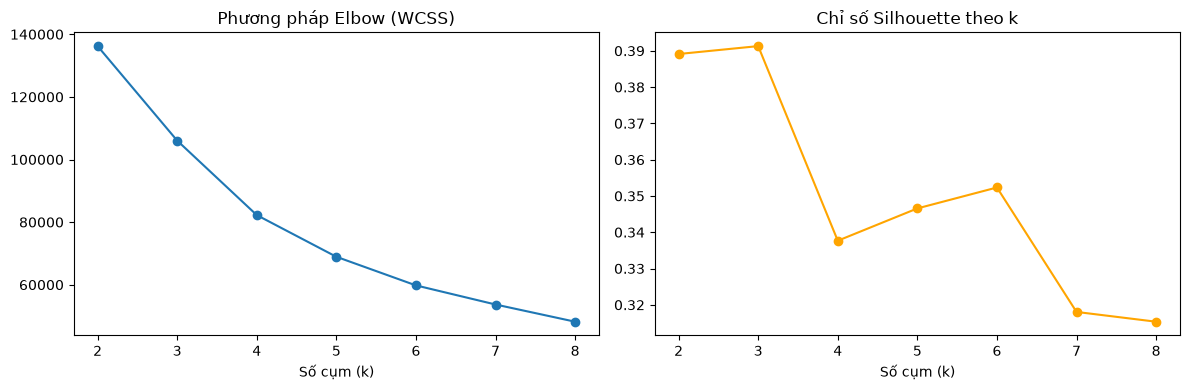


  >>> Số cụm đề xuất theo Silhouette cao nhất: k = 3
  >>> Lưu ý: nên đối chiếu thêm với biểu đồ Elbow và khả năng diễn giải kinh doanh trước khi chốt k.

  >>> Số cụm được chọn: k = 3 (tự động từ Silhouette)


In [23]:
rfm_scaled, best_k = stage4_scale_and_find_k(rfm)
chosen_k = FINAL_K if FINAL_K is not None else best_k
print(f"\n  >>> Số cụm được chọn: k = {chosen_k}" + (" (tự động từ Silhouette)" if FINAL_K is None else " (cố định từ config)"))


GIAI ĐOẠN 4.5: SO SÁNH NHIỀU THUẬT TOÁN PHÂN CỤM
  Các chỉ số được chấm trên CÙNG mẫu 3,000/75,799 khách hàng.
  Đang chạy K-Means...
  Đang chạy Spectral Clustering (trên mẫu)...


  Đang chạy Mean Shift (trên mẫu)...


  Đang chạy Gaussian Mixture Model (GMM)...


  Đang chạy DBSCAN...


  Đang chạy Fuzzy C-Means (FCM)...



  Bảng so sánh chất lượng phân cụm (tất cả chấm trên cùng một mẫu):
  Thuật toán            Số cụm  Nhiễu%  Silhouette   Davies-B.   Calinski-H.     Dunn
  -----------------------------------------------------------------------------------
  K-Means                    3     0.0       0.390       1.055       1,755.7    0.006   << Đề xuất: cân bằng tốt nhất giữa các chỉ số
  Spectral Clustering        3     0.0       0.302       1.472       1,238.0    0.158   
  Mean Shift                 2     0.0       0.390       1.082       2,001.1    0.009   
  GMM                        3     0.0       0.302       1.472       1,238.0    0.158   
  DBSCAN                     6     0.1       0.270       1.896         509.7    0.094   
  FCM                        3     0.0       0.274       1.213       1,540.2    0.001   

  Đã lưu bảng so sánh vào: outputs_rfm/algorithm_comparison.csv


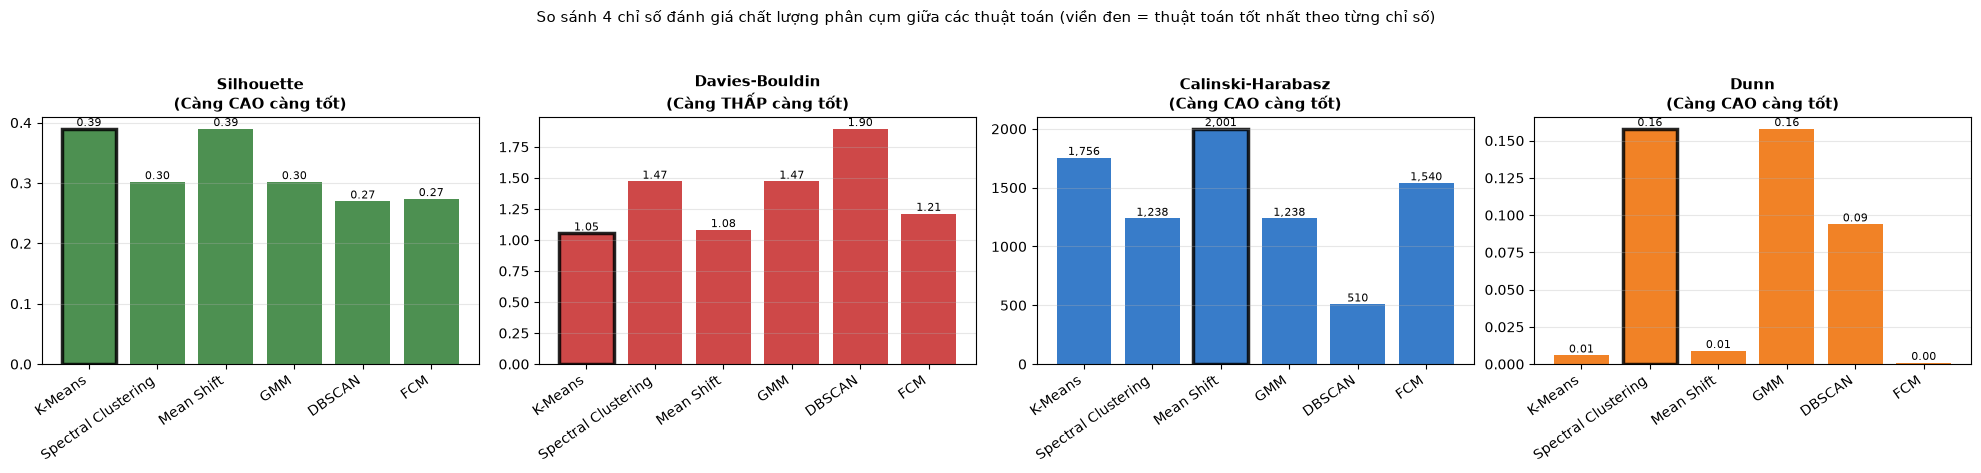

  Đã lưu biểu đồ so sánh chỉ số vào: outputs_rfm/algorithm_comparison_metrics.png


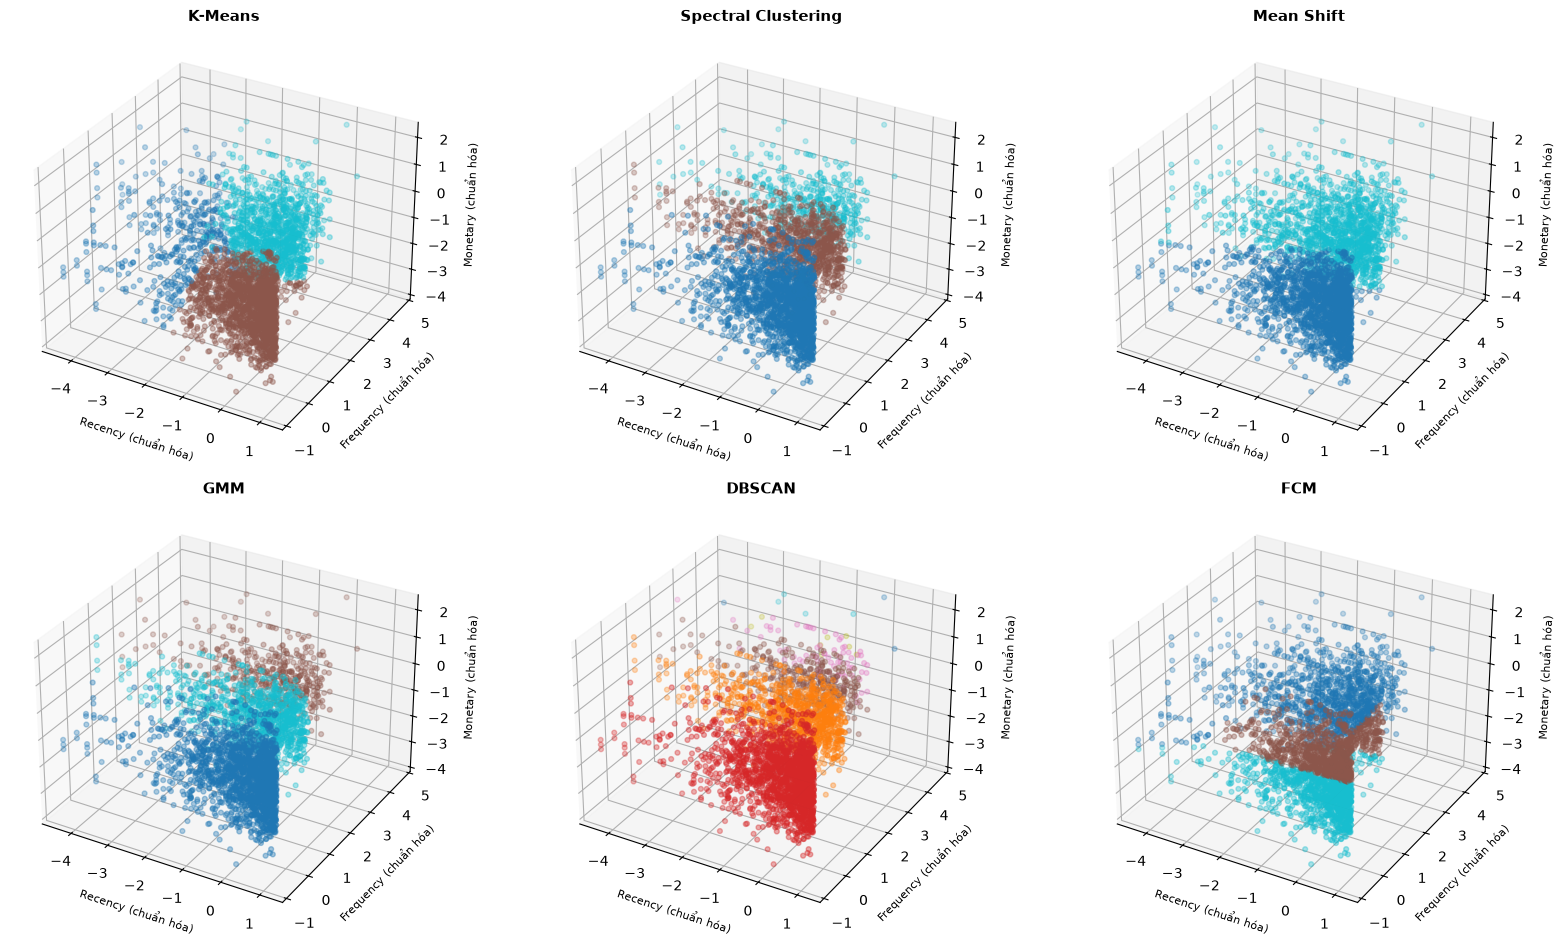

Đã lưu biểu đồ so sánh 3D vào: outputs_rfm/algorithm_comparison_3d.png


,Số cụm,Nhiễu(%),Silhouette,Davies-Bouldin,Calinski-Harabasz,Dunn,Nhận xét
Thuật toán,,,,,,,
K-Means,3,0.00,0.39,1.05,"1,755.70",0.01,<< Đề xuất: cân bằng tốt nhất giữa các chỉ số
Spectral Clustering,3,0.00,0.30,1.47,"1,238.00",0.16,
Mean Shift,2,0.00,0.39,1.08,"2,001.10",0.01,
GMM,3,0.00,0.30,1.47,"1,238.00",0.16,
DBSCAN,6,0.10,0.27,1.90,509.70,0.09,
FCM,3,0.00,0.27,1.21,"1,540.20",0.00,


In [24]:
kmeans_labels = None
comparison = None
if RUN_ALGORITHM_COMPARISON:
    comparison, _, kmeans_labels = stage4b_compare_algorithms(rfm_scaled, k=chosen_k)
comparison

In [25]:
rfm = stage5_train_kmeans(rfm, rfm_scaled, k=chosen_k, precomputed_labels=kmeans_labels)
rfm.head()


GIAI ĐOẠN 5: HUẤN LUYỆN K-MEANS VỚI k=3 & GÁN NHÃN CỤM


  Silhouette Score:            0.390   (càng cao càng tốt, tối đa 1)
  Davies-Bouldin Index:        1.068   (càng thấp càng tốt)
  Calinski-Harabasz Index:       43,376.6   (càng cao càng tốt)

  Đặc điểm từng cụm (đặt tên theo hồ sơ R/F/M):
  Tên cụm                   R TB (ngày)  F TB (lần)            M TB     Số KH    Tỷ lệ
  ------------------------------------------------------------------------------------
  At-Risk Customers               262.8         2.4             244    25,465    33.6%
  Best Customers                   35.9         1.8             157    10,174    13.4%
  Lost Customers                  401.0         1.0              80    40,160    53.0%



  Đã lưu bảng kết quả cụm vào: outputs_rfm/rfm_with_clusters.csv


,CUSTOMER_ID,Recency,Frequency,Monetary,customer_segment,membership_tier,customer_lifetime_value,customer_retention_score,customer_churn_risk,Cluster,Cluster_Name
0,C00000001,595,2,264.18,Convenience Shopper,Bronze,"12,387.34",0.52,0.08,2,At-Risk Customers
1,C00000002,420,1,350.22,Convenience Shopper,Bronze,"21,554.15",0.52,0.52,1,Lost Customers
2,C00000003,324,1,59.99,Occasional Shopper,Platinum,"3,173.86",0.57,0.37,1,Lost Customers
3,C00000004,601,1,103.76,Family Shopper,Bronze,"4,332.86",0.60,0.00,1,Lost Customers
4,C00000005,118,1,48.64,Deal Seeker,Bronze,"4,138.29",0.76,0.11,1,Lost Customers



GIAI ĐOẠN 6: TRỰC QUAN HÓA & ĐỐI CHIẾU VỚI NHÃN CÓ SẴN


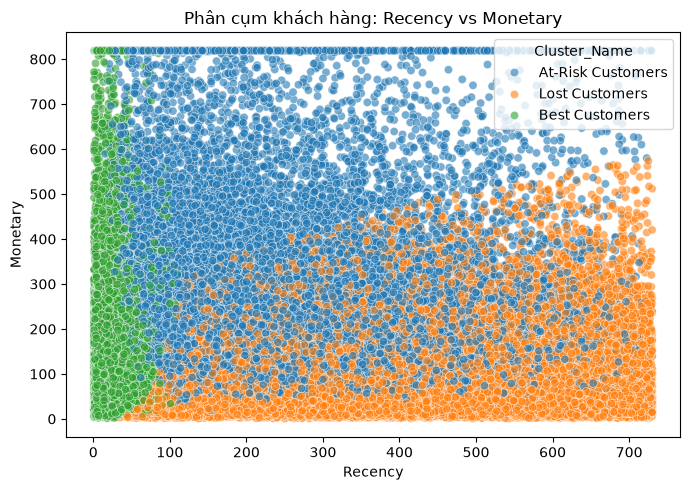

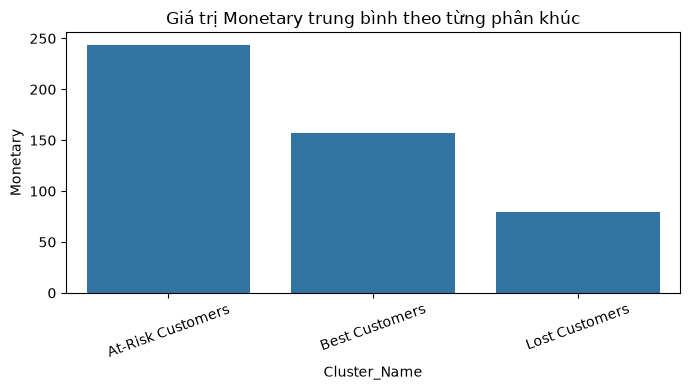

Đã lưu biểu đồ vào thư mục: outputs_rfm/

[Đối chiếu] Cluster_Name vs customer_segment (nhãn có sẵn):
customer_segment   Budget Shopper  Convenience Shopper  Deal Seeker  \
Cluster_Name                                                          
At-Risk Customers            3802                 1833         2035   
Best Customers               1513                  735          850   
Lost Customers               6006                 2856         3166   

customer_segment   Family Shopper  Loyal Customer  Occasional Shopper  \
Cluster_Name                                                            
At-Risk Customers            4558            3042                2512   
Best Customers               1843            1196                1059   
Lost Customers               7140            4799                4054   

customer_segment   Premium Shopper  Regular Shopper  
Cluster_Name                                         
At-Risk Customers             2546             5137  
Best Customers

In [26]:
stage6_visualize_and_validate(rfm, labels)

In [27]:
stage7_marketing_recommendation(rfm)

print("\n" + "=" * 70)
print("HOÀN TẤT PIPELINE. Xem toàn bộ kết quả trong thư mục:", OUTPUT_DIR)
print("=" * 70)


GIAI ĐOẠN 7: ĐỀ XUẤT CHIẾN LƯỢC MARKETING THEO TỪNG PHÂN KHÚC

  • At-Risk Customers  —  25,465 khách hàng (33.6% tổng số)
    Chiến lược đề xuất: Khách từng chi tiêu tốt nhưng lâu không quay lại: email/SMS cá nhân hóa 'chúng tôi nhớ bạn', ưu đãi quay lại có thời hạn, khảo sát nhanh lý do.

  • Best Customers  —  10,174 khách hàng (13.4% tổng số)
    Chiến lược đề xuất: Chương trình VIP, ưu đãi độc quyền, quà tặng cảm ơn, mời trải nghiệm sản phẩm mới sớm.

  • Lost Customers  —  40,160 khách hàng (53.0% tổng số)
    Chiến lược đề xuất: Khảo sát lý do rời bỏ, chiến dịch hoàn tiền/giảm giá mạnh để tái kích hoạt; giới hạn ngân sách vì giá trị thấp.

HOÀN TẤT PIPELINE. Xem toàn bộ kết quả trong thư mục: outputs_rfm
